# Eval summary — all models × methods

Bar plot comparing **mean similarity-adjusted F1** across scored papers for each model run under `outputs/`.

- **X-axis:** model (one tick per run)
- **Y-axis:** mean similarity-adjusted F1 per paper ∈ [0, 1]
  - \(F_{\mathrm{adj}} = S \times F\) (TP similarity × factual rate)
  - \(E_{\mathrm{combined}} = 2 F_{\mathrm{adj}} C / (F_{\mathrm{adj}} + C)\) (harmonic mean with completeness)
  - implemented as `f1` in `eval_utils` / `wopke_eval`
- **Bars:** one per method — `direct_llm`, `workflow`, `MAS`

Gemini and Mistral runs are excluded by default. Scoring all models can take several minutes.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

repo_root = Path.cwd().resolve()
for p in [repo_root, *repo_root.parents]:
    if (p / "src").is_dir() and (p / "outputs").is_dir():
        repo_root = p
        break

eval_dir = repo_root / "notebooks" / "eval"
if str(eval_dir) not in sys.path:
    sys.path.insert(0, str(eval_dir))

import wopke_eval as we

OUTPUTS_ROOT = repo_root / "outputs"
METHODS = list(we.METHOD_PREFIXES)

## Configuration

`METRIC` is `f1` — the similarity-adjusted F1 / combined evaluation score
\(E_{\mathrm{combined}} = 2 S F C / (S F + C)\), already computed in `eval_utils`.

`EXCLUDE_MODEL_SUBSTRINGS` drops runs whose tag contains any listed substring (default: gemini, mistral).

Optional `MODEL_TAGS` restricts which runs to score; leave `None` for all non-excluded runs.

In [2]:
import re

METRIC = "f1"
METRIC_LABEL = "similarity-adjusted F1"
EXCLUDE_MODEL_SUBSTRINGS = ("gemini", "mistral")
MODEL_TAGS: list[str] | None = None  # e.g. ["surf_Qwen-Qwen3-6-27B-FP8_42fields"]
SHOW_PROGRESS = True

# After ranking by score, swap these two short names' x-axis positions.
SWAP_MODEL_PAIR = ("openai-gpt-oss-120b", "Sehyo-Qwen3-5-122B-A10B-NVFP4")

# Bar colors for direct_llm, workflow, MAS
METHOD_PLOT_COLORS = {
    "direct_llm": "#007DCC",
    "workflow": "#FFB900",
    "MAS": "#D10056",
}
METHOD_LABELS = {
    "direct_llm": "Direct",
    "workflow": "Workflow",
    "MAS": "MAS",
}

_SIZE_PART_RE = re.compile(r"^\d+[Bb]")


def short_model_name(tag: str) -> str:
    s = tag.removeprefix("surf_").removesuffix("_42fields")
    return s


def display_model_label(model: str) -> str:
    """Axis label: drop vendor prefix; size on its own line when a suffix follows."""
    if model == "default-text-large":
        return "Llama\n70b"
    # Remove first segment before the first dash (vendor / org prefix)
    rest = model.split("-", 1)[1] if "-" in model else model
    parts = rest.split("-")
    split_at = next((i for i, p in enumerate(parts) if _SIZE_PART_RE.match(p)), None)
    if split_at is None:
        if len(parts) >= 2:
            return f"{parts[0]}\n{'-'.join(parts[1:])}"
        return rest
    if split_at == 0:
        # e.g. unexpected leading size token — still force 2 lines when possible
        if len(parts) >= 2:
            return f"{parts[0]}\n{'-'.join(parts[1:])}"
        return rest
    name = "-".join(parts[:split_at])
    size = parts[split_at]
    suffix = parts[split_at + 1 :]
    # 3 lines when there is a post-size suffix (e.g. Qwen3-6 / 35B / A3B-FP8)
    if suffix:
        return f"{name}\n{size}\n{'-'.join(suffix)}"
    return f"{name}\n{size}"


def is_excluded_model(tag: str) -> bool:
    t = tag.lower()
    return any(s in t for s in EXCLUDE_MODEL_SUBSTRINGS)


def apply_model_order_swaps(order: list[str], pair: tuple[str, str] = SWAP_MODEL_PAIR) -> list[str]:
    """Keep ranking order, but swap the two named models if both are present."""
    a, b = pair
    if a not in order or b not in order:
        return order
    out = list(order)
    i, j = out.index(a), out.index(b)
    out[i], out[j] = out[j], out[i]
    return out

## Score all models

Mean per method is the average of per-paper scores over papers in each run.

Two aggregates are built from the same paper-level scores:

1. **All scored papers** — every paper id in the run (missing method CSVs count as empty preds).
2. **Complete papers only** — papers where **all three methods** have a non-empty prediction CSV (`n_pred > 0`).

In [3]:
inventory = we.list_model_runs(OUTPUTS_ROOT)
if MODEL_TAGS is not None:
    tags = [t for t in MODEL_TAGS if t in set(inventory["tag"])]
    missing = sorted(set(MODEL_TAGS) - set(tags))
    if missing:
        print("Skipping unknown tags:", missing)
else:
    tags = inventory["tag"].tolist()

tags = [t for t in tags if not is_excluded_model(t)]
excluded = inventory.loc[inventory["tag"].map(is_excluded_model), "tag"].tolist()
if excluded:
    print("Excluded:", excluded)

print(f"Scoring {len(tags)} model(s)")
inventory.loc[inventory["tag"].isin(tags)]

Excluded: ['google_gemini-2-5-flash_42fields', 'surf_mistralai-Mistral-Small-3-2-24B-Instruct-2506_42fields']
Scoring 6 model(s)


,tag,run_dir,n_papers,n_direct_llm,n_workflow,n_MAS
1,surf_Qwen-Qwen3-6-27B-FP8_42fields,/home/com3dian/Github/meta_analysis_agents/out...,62,48,46,62
2,surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields,/home/com3dian/Github/meta_analysis_agents/out...,87,86,76,86
3,surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields,/home/com3dian/Github/meta_analysis_agents/out...,81,70,65,80
4,surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields,/home/com3dian/Github/meta_analysis_agents/out...,81,71,68,80
5,surf_default-text-large_42fields,/home/com3dian/Github/meta_analysis_agents/out...,78,75,76,77
7,surf_openai-gpt-oss-120b_42fields,/home/com3dian/Github/meta_analysis_agents/out...,81,76,75,81


In [4]:
METRIC_COLS = (*we.STACK_METRIC_KEYS, we.OVERALL_SCORE_KEY, "f1", "stacked_total")


def mean_summary_from_papers(papers: pd.DataFrame) -> pd.DataFrame:
    """Average per-paper metrics → one row per (model, method)."""
    rows: list[dict] = []
    if papers.empty:
        return pd.DataFrame(rows)
    for (tag, model), sub in papers.groupby(["model_tag", "model"], sort=False):
        mean_df = we.overall_mean_metrics_df(sub)
        for _, r in mean_df.iterrows():
            rows.append(
                {
                    "model_tag": tag,
                    "model": model,
                    "method": r["method"],
                    "n_papers": int(r["n_papers"]),
                    **{k: float(r[k]) for k in METRIC_COLS},
                }
            )
    return pd.DataFrame(rows)


def papers_with_all_methods(papers: pd.DataFrame, methods: list[str] = METHODS) -> pd.DataFrame:
    """Keep papers where every method has a non-empty prediction (`n_pred > 0`)."""
    parts: list[pd.DataFrame] = []
    for _, sub in papers.groupby("model_tag", sort=False):
        pivot = sub.pivot_table(
            index="paper_id", columns="method", values="n_pred", aggfunc="max"
        )
        for m in methods:
            if m not in pivot.columns:
                pivot[m] = 0.0
        ok_ids = pivot.index[pivot[list(methods)].fillna(0).gt(0).all(axis=1)]
        parts.append(sub[sub["paper_id"].isin(ok_ids)])
    if not parts:
        return papers.iloc[0:0].copy()
    return pd.concat(parts, ignore_index=True)


def _paper_metric_dict(r: pd.Series) -> dict[str, float]:
    """Pull scoring columns from a paper metrics row; compute stacked_total if missing."""
    out = {k: float(r[k]) for k in (*we.STACK_METRIC_KEYS, we.OVERALL_SCORE_KEY, "f1")}
    if "stacked_total" in r.index and pd.notna(r["stacked_total"]):
        out["stacked_total"] = float(r["stacked_total"])
    else:
        out["stacked_total"] = sum(out[k] for k in we.STACK_METRIC_KEYS)
    return out


paper_rows: list[dict] = []
for tag in tqdm(tags, desc="models"):
    run = we.load_model_run(tag, outputs_root=OUTPUTS_ROOT)
    metrics_df = we.all_papers_metrics_df(run, show_progress=SHOW_PROGRESS)
    model = short_model_name(tag)
    for _, r in metrics_df.iterrows():
        paper_rows.append(
            {
                "model_tag": tag,
                "model": model,
                "paper_id": int(r["paper_id"]),
                "method": r["method"],
                "n_pred": int(r["n_pred"]),
                "n_gt": int(r["n_gt"]),
                **_paper_metric_dict(r),
            }
        )

papers_df = pd.DataFrame(paper_rows)
summary_df = mean_summary_from_papers(papers_df)

papers_complete_df = papers_with_all_methods(papers_df)
summary_complete_df = mean_summary_from_papers(papers_complete_df)

print("All papers:")
print(summary_df.groupby("model")["n_papers"].first().to_string())
print("\nComplete papers (all 3 methods have n_pred > 0):")
if summary_complete_df.empty:
    print("  (none)")
else:
    print(summary_complete_df.groupby("model")["n_papers"].first().to_string())

summary_df

models:   0%|          | 0/6 [00:00<?, ?it/s]

Scoring papers:   0%|          | 0/186 [00:00<?, ?it/s]

Scoring papers:   0%|          | 0/261 [00:00<?, ?it/s]

Scoring papers:   0%|          | 0/243 [00:00<?, ?it/s]

Scoring papers:   0%|          | 0/243 [00:00<?, ?it/s]

Scoring papers:   0%|          | 0/234 [00:00<?, ?it/s]

Scoring papers:   0%|          | 0/243 [00:00<?, ?it/s]

All papers:
model
Qwen-Qwen3-6-27B-FP8             62
Qwen-Qwen3-6-35B-A3B-FP8         87
RedHatAI-gemma-4-31B-it-NVFP4    81
Sehyo-Qwen3-5-122B-A10B-NVFP4    81
default-text-large               78
openai-gpt-oss-120b              81

Complete papers (all 3 methods have n_pred > 0):
model
Qwen-Qwen3-6-27B-FP8             37
Qwen-Qwen3-6-35B-A3B-FP8         51
RedHatAI-gemma-4-31B-it-NVFP4    60
Sehyo-Qwen3-5-122B-A10B-NVFP4    39
default-text-large               52
openai-gpt-oss-120b              65


,model_tag,model,method,n_papers,similarity,factual_rate,retrieval_rate,overall_score,f1,stacked_total
0,surf_Qwen-Qwen3-6-27B-FP8_42fields,Qwen-Qwen3-6-27B-FP8,direct_llm,62,0.623576,0.603624,0.596471,0.491457,0.508048,1.823671
1,surf_Qwen-Qwen3-6-27B-FP8_42fields,Qwen-Qwen3-6-27B-FP8,workflow,62,0.509134,0.504749,0.398121,0.390229,0.330639,1.412004
2,surf_Qwen-Qwen3-6-27B-FP8_42fields,Qwen-Qwen3-6-27B-FP8,MAS,62,0.629413,0.611210,0.594789,0.491662,0.501968,1.835413
3,surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields,Qwen-Qwen3-6-35B-A3B-FP8,direct_llm,87,0.757548,0.717595,0.725825,0.550779,0.577402,2.200968
4,surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields,Qwen-Qwen3-6-35B-A3B-FP8,workflow,87,0.653048,0.632241,0.645005,0.475056,0.503523,1.930294
5,surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields,Qwen-Qwen3-6-35B-A3B-FP8,MAS,87,0.469469,0.406280,0.513745,0.293523,0.340447,1.389494
6,surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields,RedHatAI-gemma-4-31B-it-NVFP4,direct_llm,81,0.664990,0.599937,0.633771,0.472042,0.505603,1.898699
7,surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields,RedHatAI-gemma-4-31B-it-NVFP4,workflow,81,0.599682,0.537730,0.549122,0.403822,0.427790,1.686534
8,surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields,RedHatAI-gemma-4-31B-it-NVFP4,MAS,81,0.589966,0.673382,0.583318,0.481429,0.481734,1.846667
9,surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields,Sehyo-Qwen3-5-122B-A10B-NVFP4,direct_llm,81,0.690361,0.572243,0.685337,0.452219,0.509931,1.947942


## Bar plot — all scored papers

Grouped bars over **every** paper in each run (missing method outputs scored as empty). Each model has three bars (methods); each bar is the mean similarity-adjusted F1.

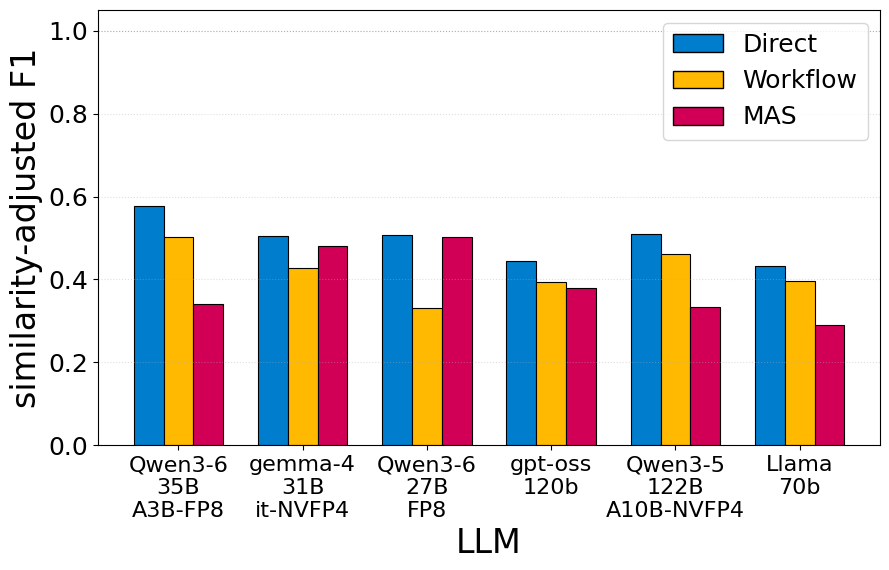

In [5]:
from matplotlib.patches import Patch

EVAL_SUMMARY_DIR = repo_root / "outputs" / "eval_summary"


def plot_method_bars(
    summary: pd.DataFrame,
    *,
    model_order: list[str] | None = None,
    bar_width: float = 0.24,
    save_path: Path | None = None,
) -> list[str]:
    """Grouped bars: x=models, 3 methods side-by-side, solid similarity-adjusted F1."""
    if summary.empty:
        print("No data to plot.")
        return []
    if model_order is None:
        model_order = (
            summary.groupby("model")[METRIC]
            .mean()
            .sort_values(ascending=False)
            .index.tolist()
        )
        model_order = apply_model_order_swaps(model_order)

    methods = [m for m in METHODS if m in set(summary["method"])]
    x = np.arange(len(model_order))
    offsets = (np.arange(len(methods)) - (len(methods) - 1) / 2) * bar_width

    fig, ax = plt.subplots(figsize=(max(9, len(model_order) * 1.35), 5.8))
    for mi, method in enumerate(methods):
        sub = summary[summary["method"] == method].set_index("model")
        color = METHOD_PLOT_COLORS.get(method, "steelblue")
        heights = [
            float(sub.loc[model, METRIC]) if model in sub.index else 0.0
            for model in model_order
        ]
        ax.bar(
            x + offsets[mi],
            heights,
            width=bar_width,
            color=color,
            edgecolor="black",
            linewidth=0.8,
            label=METHOD_LABELS.get(method, method),
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [display_model_label(m) for m in model_order],
        rotation=0,
        ha="center",
        fontsize=16,
    )
    ax.set_ylabel(METRIC_LABEL, fontsize=24)
    ax.set_xlabel("LLM", fontsize=24)
    ax.tick_params(axis="y", labelsize=18)
    ax.set_ylim(0, 1.05)
    ax.axhline(1.0, color="gray", linestyle=":", linewidth=0.8, alpha=0.5)

    method_handles = [
        Patch(
            facecolor=METHOD_PLOT_COLORS.get(m, "steelblue"),
            edgecolor="black",
            label=METHOD_LABELS.get(m, m),
        )
        for m in methods
    ]
    ax.legend(handles=method_handles, loc="upper right", fontsize=18)
    ax.grid(axis="y", linestyle=":", alpha=0.4)
    plt.tight_layout()
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
        print(f"saved {save_path}")
    plt.show()
    return model_order


model_order = plot_method_bars(
    summary_df,
    save_path=EVAL_SUMMARY_DIR / "eval_summary_all_papers.pdf",
)

## Bar plot — complete papers only (all 3 methods)

Same bar chart, averaged only over papers where **direct_llm**, **workflow**, and **MAS** each have a non-empty prediction (`n_pred > 0`). Model order matches the all-papers plot.

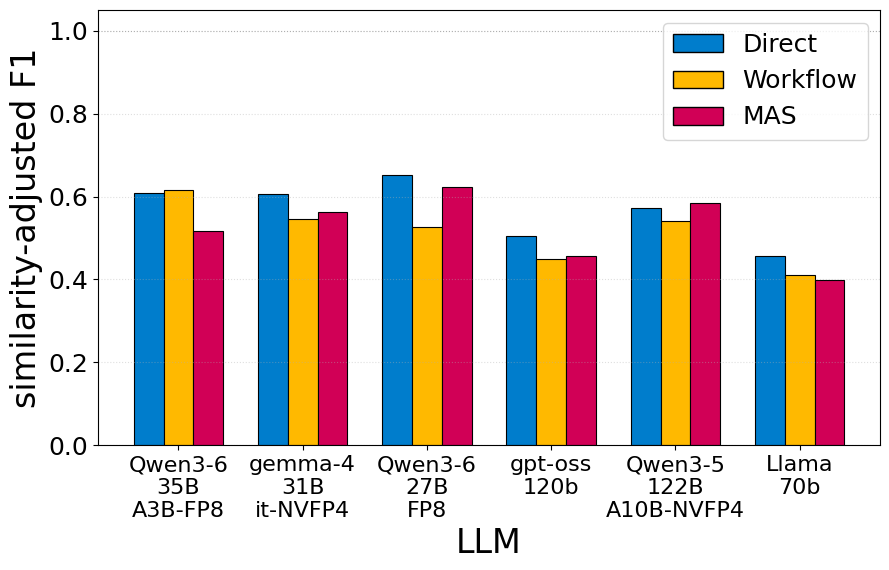

['Qwen-Qwen3-6-35B-A3B-FP8',
 'RedHatAI-gemma-4-31B-it-NVFP4',
 'Qwen-Qwen3-6-27B-FP8',
 'openai-gpt-oss-120b',
 'Sehyo-Qwen3-5-122B-A10B-NVFP4',
 'default-text-large']

In [6]:
summary_complete_df

plot_method_bars(
    summary_complete_df,
    model_order=model_order if model_order else None,
    save_path=EVAL_SUMMARY_DIR / "eval_summary_complete_papers.pdf",
)